---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 3"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 14. Одновібратори</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>3.18. Одновібратори на операційному підсилювачі: основні розрахункові співвідношення та діаграми роботи</li>
  <li>3.19. Одновібратори на логічних елементах: основні розрахункові співвідношення та діаграми роботи</li>
  <li>3.20. Одновібратори на інтегральному таймері: основні розрахункові співвідношення та діаграми роботи</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 14 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Вступ: чекальні генератори](#intro)
* [Одновібратор на ОП](#opamp-oneshot)
    * [🔬 Інтерактивно: одновібратор на μA741 (PySpice)](#opamp-oneshot-interactive)
* [Одновібратори на логічних елементах](#gate-oneshot)
    * [🔬 Інтерактивно: одновібратор на КМОН-елементах АБО-НЕ (PySpice)](#cmos-oneshot-interactive)
* [Одновібратор на інтегральному таймері 555](#oneshot-555)
    * [🔬 Інтерактивно: одновібратор на таймері 555 (PySpice)](#ne555-oneshot-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Вступ: чекальні генератори <a class="anchor" id="intro"></a>

**Одновібратор (чекальний мультивібратор, моностабільний мультивібратор)** має **один стійкий стан**, у якому може перебувати як завгодно довго, і один **квазістійкий** (тимчасово стійкий). Короткий запускальний імпульс переводить його в квазістійкий стан, з якого він самостійно повертається через час $t_і$, заданий RC-колом. Отже, одновібратор формує **один імпульс нормованої тривалості** на кожен запуск, незалежно від тривалості і форми запускального сигналу.

**Параметри:** тривалість вихідного імпульсу $t_і$; **час відновлення** $t_{від}$ — час, потрібний RC-колу, щоб повернутися у вихідний стан (до його закінчення повторний запуск дає коротший імпульс); мінімальний період запуску $T_{min} = t_і + t_{від}$; допустима тривалість і амплітуда запускального імпульсу.

**Застосування:** формування імпульсів заданої тривалості (усунення брязкоту кнопок і контактів), затримка сигналів (затримка фронту на $t_і$), розширення коротких імпульсів, сторожові таймери (watchdog), детектори пропуску імпульсів, імпульсні частотоміри і тахометри (середнє значення послідовності нормованих імпульсів пропорційне частоті), ШІМ (одновібратор із запуском від генератора і керованою $t_і$).

---

## Одновібратор на ОП <a class="anchor" id="opamp-oneshot"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.18</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати, як діод у колі конденсатора перетворює мультивібратор на ОП на одновібратор
> - Виводити тривалість імпульсу і час відновлення
> - Будувати часові діаграми одновібратора на ОП

</div>

Одновібратор отримують з мультивібратора на ОП (тема 13), заборонивши одне з перемикань: паралельно конденсатору $C$ вмикають **діод VD1**, який обмежує напругу $u_C$ на рівні $U_{пр} \approx 0{,}6$ В.

**Стійкий стан.** $U_{вих} = +U_{нас}$, конденсатор заряджений до $U_{пр}$ (далі не заряджається — діод відкритий), на неінвертувальному вході $\gamma U_{нас} > U_{пр}$, де $\gamma = R_1/(R_1 + R_2)$ — тож стан стійкий.

**Запуск.** Короткий від'ємний імпульс на неінвертувальному вході (через розділювальний конденсатор $C_з$, у практичних схемах — ще й через діод) робить $U_+ < u_C$: ОП перемикається, $U_{вих} = -U_{нас}$, поріг стає $-\gamma U_{нас}$. Діод закривається, і $C$ перезаряджається через $R$ від $U_{пр}$ з прагненням до $-U_{нас}$. Коли $u_C = -\gamma U_{нас}$, ОП повертається в стійкий стан.

**Тривалість імпульсу:**
$$t_і = RC\ln\frac{U_{нас} + U_{пр}}{U_{нас} - \gamma U_{нас}} = RC\ln\frac{1 + U_{пр}/U_{нас}}{1 - \gamma}\approx RC\ln\frac{1}{1 - \gamma}.$$
При $R_1 = R_2$ ($\gamma = 0{,}5$): $t_і \approx 0{,}69RC$.

**Відновлення.** Після імпульсу $C$ перезаряджається від $-\gamma U_{нас}$ до $U_{пр}$ через $R$: $t_{від} = RC\ln\frac{1 + \gamma}{1 - U_{пр}/U_{нас}} \approx RC\ln(1 + \gamma)$. Для прискорення відновлення паралельно $R$ вмикають діод з малим резистором.

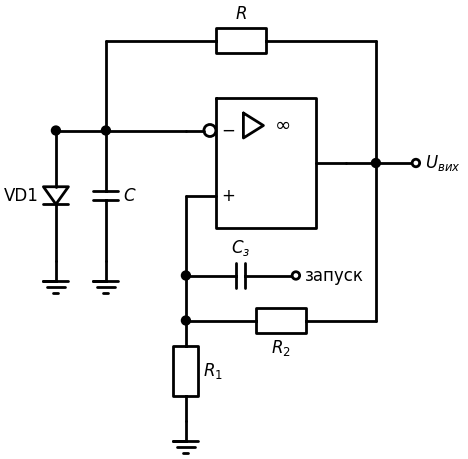

In [2]:
# Одновібратор на ОП: VD1 обмежує напругу на C у стійкому стані, запуск — через C_з
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (o := OpAmp().at((2.6, 2)).anchor('in1'))
        d += W((1.0, 2), (2.6, 2)); d += elm.Dot().at((1.0, 2)); d += elm.Dot().at((0.0, 2))
        d += elm.Capacitor().at((1.0, 2)).to((1.0, -0.6)).label('$C$', loc='bottom'); d += elm.Ground().at((1.0, -0.6))
        d += W((1.0, 2), (0.0, 2)); d += elm.Diode().at((0.0, 2)).to((0.0, -0.6)).label('VD1', loc='top'); d += elm.Ground().at((0.0, -0.6))
        d += W((1.0, 2), (1.0, 3.8)); d += elm.Resistor().at((1.0, 3.8)).to((6.4, 3.8)).label('$R$'); d += W((6.4, 3.8), (6.4, o.out[1]))
        d += elm.Dot().at((6.4, o.out[1])); d += W(o.out, (7.2, o.out[1])); d += elm.Dot(open=True).at((7.2, o.out[1])).label('$U_{вих}$', loc='right')
        xp = o.in2[0]
        d += W(o.in2, (xp, -1.8)); d += elm.Dot().at((xp, -1.8))
        d += elm.Resistor().at((xp, -1.8)).to((xp, -3.8)).label('$R_1$', loc='bottom'); d += elm.Ground().at((xp, -3.8))
        d += elm.Resistor().at((xp, -1.8)).to((6.4, -1.8)).label('$R_2$', loc='bottom'); d += W((6.4, -1.8), (6.4, o.out[1]))
        d += elm.Dot().at((xp, -0.9)); d += elm.Capacitor().at((xp, -0.9)).to((xp + 2.2, -0.9)).label('$C_з$', loc='top')
        d += elm.Dot(open=True).at((xp + 2.2, -0.9)).label('запуск', loc='right')

---
### 🔬 Інтерактивно: одновібратор на μA741 (PySpice) <a class="anchor" id="opamp-oneshot-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Одновібратор за схемою вище ($R = 10$ кОм, $R_1 = R_2 = 10$ кОм, $C_з = 10$ нФ). У момент 3 мс подається запускальний імпульс −10 В. Змінюйте $C$ і $R_1$: тривалість імпульсу відповідає формулі $t_і = RC\ln\frac{1 + U_{пр}/U_{нас}}{1 - \gamma}$; після імпульсу видно інтервал відновлення (перезаряд $C$ до $+0{,}6$ В).

</div>

In [3]:
# Одновібратор на μA741: запуск від'ємним імпульсом через C_з
def opamp_oneshot(C_nF=100.0, R1_k=10.0):
    R, C = 10e3, C_nF * 1e-9
    c = opamp_circuit('one-shot')
    c.model('D', 'D', IS=2.5e-9, N=1.75)
    c.R('f', 'out', 'm', R); c.C(1, 'm', c.gnd, C); c.D(1, 'm', c.gnd, model='D')
    c.R(1, 'p', c.gnd, R1_k * 1e3); c.R(2, 'out', 'p', 10e3)
    c.PulseVoltageSource('t', 'tr', c.gnd, initial_value=0, pulsed_value=-10, delay_time=3e-3, rise_time=1e-6,
                         fall_time=2e-3, pulse_width=10e-6, period=1)              # повільний спад — без повторного запуску
    c.C('z', 'tr', 'p', 10e-9)
    add_opamp(c, 1, 'p', 'm', 'out')
    g = R1_k / (R1_k + 10)
    ti0 = R * C * np.log((1 + 0.6 / 13.2) / (1 - g))
    t, v = tran(c, 2e-6, 3e-3 + 3 * ti0 + 1e-3, start=2.5e-3)
    u = v['out']; dn = t[1:][(u[1:] < 0) & (u[:-1] >= 0)]; up = t[1:][(u[1:] > 0) & (u[:-1] <= 0)]
    ti = (up[up > dn[0]][0] - dn[0]) if len(dn) and np.any(up > dn[0]) else np.nan
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
    a1.plot(t * 1e3, v['tr'], color='#9E9E9E', label='запуск'); a1.set_ylabel('В'); a1.legend(loc='lower right')
    a2.plot(t * 1e3, u, color='#F44336', label='$u_{вих}$'); a2.plot(t * 1e3, v['m'], color='#2196F3', label='$u_C$'); a2.plot(t * 1e3, v['p'], color='#4CAF50', lw=1, label='$U_+$')
    a2.set_xlabel('t, мс'); a2.set_ylabel('В'); a2.legend(loc='lower right', fontsize=9)
    a2.set_title(f'tі = {ti*1e3:.3f} мс;  формула {ti0*1e3:.3f} мс  (γ = {g:.2f})')
    plt.tight_layout(); plt.show()

interact(opamp_oneshot,
         C_nF=widgets.FloatSlider(min=20, max=200, step=5, value=100, description='C (нФ)'),
         R1_k=widgets.FloatSlider(min=3, max=30, step=1, value=10, description='R1 (кОм)'));

interactive(children=(FloatSlider(value=100.0, description='C (нФ)', max=200.0, min=20.0, step=5.0), FloatSlid…

---

## Одновібратори на логічних елементах <a class="anchor" id="gate-oneshot"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.19</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу одновібратора на двох елементах АБО-НЕ (І-НЕ) з RC-колом
> - Розраховувати тривалість імпульсу з урахуванням порогу логічного елемента
> - Знати спеціалізовані мікросхеми одновібраторів (74HC123, CD4538)

</div>

**Одновібратор на двох елементах АБО-НЕ (КМОН).** DD1 — двовходовий АБО-НЕ (на один вхід — запуск, на другий — вихід DD2); вихід DD1 через конденсатор $C$ подано на вхід інвертора DD2, вхід DD2 через резистор $R$ підтягнуто до $E_ж$.

- **Стійкий стан:** вхід DD2 = $E_ж$ (через $R$), вихід DD2 = 0; запуск = 0 → вихід DD1 = 1; конденсатор заряджений до 0 В (обидві обкладки ≈ $E_ж$).
- **Запуск:** короткий додатний імпульс на вхід DD1 → його вихід стрибає в 0; стрибок $-E_ж$ передається через $C$ на вхід DD2 (майже до 0) → вихід DD2 = 1, він утримує DD1 у стані 0 і після закінчення запуску.
- **Квазістійкий стан:** $C$ заряджається через $R$, напруга на вході DD2 зростає до порогу $U_{пор}$; тоді DD2 → 0, DD1 → 1 — схема повертається.

$$t_і = RC\ln\frac{E_ж}{E_ж - U_{пор}}\;\Rightarrow\;t_і \approx RC\ln2 \approx 0{,}69RC\quad(U_{пор} = E_ж/2).$$

**Особливості:** тривалість залежить від порогу елемента (розкид ±10…20 %); запускальний імпульс має бути коротшим за $t_і$ (інакше вихід триває, доки діє запуск) — для довгих сигналів запуску на вході ставлять диференціювальне коло; повторний запуск під час імпульсу ігнорується (схема **неперезапускувана**).

**Інтегральні одновібратори** 74HC123, CD4538 (два в корпусі): запуск фронтом або спадом, **перезапускувані** (повторний запуск подовжує імпульс — основа сторожових таймерів і детекторів пропуску імпульсів), вхід скидання; $t_і \approx kR_xC_x$ ($k \approx 0{,}45\ldots1$ залежно від мікросхеми).

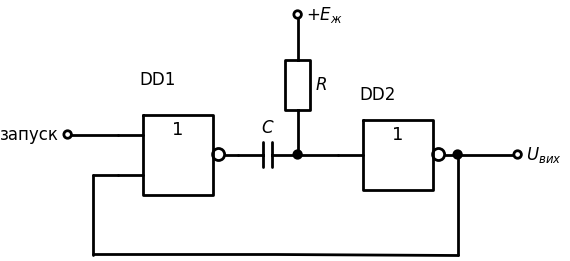

In [4]:
# Одновібратор на елементах АБО-НЕ (КМОН)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (g1 := Gate('1', 2).at((1.0, 2.0)).anchor('in1')); d += elm.Label().at((1.7, 3.0)).label('DD1')
        d += elm.Dot(open=True).at((0, g1.in1[1])).label('запуск', loc='left'); d += W((0, g1.in1[1]), g1.in1)
        d += (g2 := Gate('1', 1).at((5.4, g1.out[1])).anchor('in1')); d += elm.Label().at((6.1, g1.out[1] + 1.1)).label('DD2')
        d += elm.Capacitor().at(g1.out).to((4.6, g1.out[1])).label('$C$'); d += elm.Dot().at((4.6, g1.out[1])); d += W((4.6, g1.out[1]), g2.in1)
        d += elm.Resistor().at((4.6, g1.out[1])).to((4.6, 4.4)).label('$R$', loc='bottom'); d += elm.Dot(open=True).at((4.6, 4.4)).label('$+E_ж$', loc='right')
        d += elm.Dot().at(g2.out); d += W(g2.out, (g2.out[0] + 1.2, g2.out[1])); d += elm.Dot(open=True).at((g2.out[0] + 1.2, g2.out[1])).label('$U_{вих}$', loc='right')
        d += W(g2.out, (g2.out[0], -0.4)); d += W((g2.out[0], -0.4), (0.5, -0.4)); d += W((0.5, -0.4), (0.5, g1.in2[1])); d += W((0.5, g1.in2[1]), g1.in2)

---
### 🔬 Інтерактивно: одновібратор на КМОН-елементах АБО-НЕ (PySpice) <a class="anchor" id="cmos-oneshot-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Елементи АБО-НЕ та інвертор побудовано з МДН-транзисторів ($E_ж = 5$ В, поріг ≈ 2,5 В). Запуск — імпульс 2 мкс на 20-й мікросекунді. Змінюйте $R$ і $C$ та порівнюйте тривалість вихідного імпульсу з формулою $0{,}69RC$; зверніть увагу на напругу на вході DD2 (вузол $x$): після запуску вона падає майже до нуля і експоненційно зростає до порогу.

</div>

In [5]:
# Одновібратор на КМОН-елементах АБО-НЕ
def cmos_oneshot(R_k=10.0, C_nF=10.0):
    R, C = R_k * 1e3, C_nF * 1e-9
    c = Circuit('CMOS one-shot')
    c.model('NM', 'NMOS', LEVEL=1, VTO=1.0, KP=200e-6, LAMBDA=0.02); c.model('PM', 'PMOS', LEVEL=1, VTO=-1.0, KP=200e-6, LAMBDA=0.02)
    c.V('dd', 'vdd', c.gnd, 5)
    def nor(n, a, b, o):                       # АБО-НЕ: два n-МДН паралельно, два p-МДН послідовно
        c.MOSFET(n + 'na', o, a, c.gnd, c.gnd, model='NM', l=1e-6, w=10e-6); c.MOSFET(n + 'nb', o, b, c.gnd, c.gnd, model='NM', l=1e-6, w=10e-6)
        c.MOSFET(n + 'pa', n + 'm', a, 'vdd', 'vdd', model='PM', l=1e-6, w=20e-6); c.MOSFET(n + 'pb', o, b, n + 'm', 'vdd', model='PM', l=1e-6, w=20e-6)
    def inv(n, i, o):
        c.MOSFET(n + 'n', o, i, c.gnd, c.gnd, model='NM', l=1e-6, w=10e-6); c.MOSFET(n + 'p', o, i, 'vdd', 'vdd', model='PM', l=1e-6, w=10e-6)
    c.PulseVoltageSource('t', 'trig', c.gnd, initial_value=0, pulsed_value=5, delay_time=20e-6, rise_time=0.1e-6, fall_time=0.1e-6, pulse_width=2e-6, period=1)
    nor('1', 'trig', 'q', 'o1'); c.C(1, 'o1', 'x', C); c.R(1, 'x', 'vdd', R); inv('2', 'x', 'q')
    ti0 = 0.693 * R * C
    t, v = tran(c, ti0 / 500, 20e-6 + 2.5 * ti0)
    q = v['q']; up = t[1:][(q[1:] > 2.5) & (q[:-1] <= 2.5)]; dn = t[1:][(q[1:] < 2.5) & (q[:-1] >= 2.5)]
    ti = (dn[0] - up[0]) if len(up) and len(dn) else np.nan
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t * 1e6, v['trig'], color='#9E9E9E', label='запуск'); ax.plot(t * 1e6, q, color='#F44336', label='вихід DD2')
    ax.plot(t * 1e6, v['x'], color='#2196F3', label='вхід DD2 (x)'); ax.axhline(2.5, color='k', ls=':', lw=1)
    ax.set_xlabel('t, мкс'); ax.set_ylabel('В'); ax.legend(loc='center right', fontsize=9)
    ax.set_title(f'tі = {ti*1e6:.1f} мкс;  формула 0,69RC = {ti0*1e6:.1f} мкс')
    plt.tight_layout(); plt.show()

interact(cmos_oneshot,
         R_k=widgets.FloatSlider(min=2, max=50, step=1, value=10, description='R (кОм)'),
         C_nF=widgets.FloatSlider(min=1, max=50, step=1, value=10, description='C (нФ)'));

interactive(children=(FloatSlider(value=10.0, description='R (кОм)', max=50.0, min=2.0, step=1.0), FloatSlider…

---

## Одновібратор на інтегральному таймері 555 <a class="anchor" id="oneshot-555"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.20</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу таймера 555 в чекальному режимі
> - Розраховувати тривалість імпульсу $t_і = 1{,}1RC$
> - Знати вимоги до запускального імпульсу і способи скидання

</div>

У чекальному режимі вхід TRG (2) — вхід запуску (у стані очікування — високий рівень), виводи THR (6) і DIS (7) з'єднані з конденсатором $C$, який через резистор $R$ підключено до $E_ж$.

- **Стійкий стан:** тригер скинутий, вихід = 0, розрядний транзистор відкритий і тримає $C$ розрядженим ($u_C \approx 0$).
- **Запуск:** короткий спад на TRG нижче $\frac13E_ж$ — нижній компаратор встановлює тригер: вихід = 1, розрядний транзистор закривається, $C$ заряджається через $R$.
- **Повернення:** коли $u_C = \frac23E_ж$, верхній компаратор скидає тригер: вихід = 0, $C$ швидко розряджається.

$$t_і = RC\ln\frac{E_ж}{E_ж - \frac23E_ж} = RC\ln3 \approx 1{,}1RC .$$
Тривалість не залежить від напруги живлення; діапазон — від мікросекунд до годин ($R$ до десятків МОм, $C$ — сотні мкФ, але з урахуванням струму витоку).

**Вимоги і особливості:** запускальний імпульс має бути коротшим за $t_і$ (інакше вихід утримується в 1, доки TRG < $\frac13E_ж$ — використовують диференціювальне коло $C_зR_з$ на вході); повторний запуск під час імпульсу не подовжує його; вхід RST (4) негайно перериває імпульс; напруга на CTL (5) змінює поріг і, отже, $t_і$ — так будують **широтно-імпульсний модулятор** (одновібратор запускається від генератора, а модулювальна напруга подається на CTL).

**Застосування:** формувачі імпульсів від кнопок і датчиків, реле часу (затримка вимкнення освітлення), детектори пропуску імпульсів (з транзистором розряду $C$ від вхідних імпульсів), ШІМ, подільники частоти.

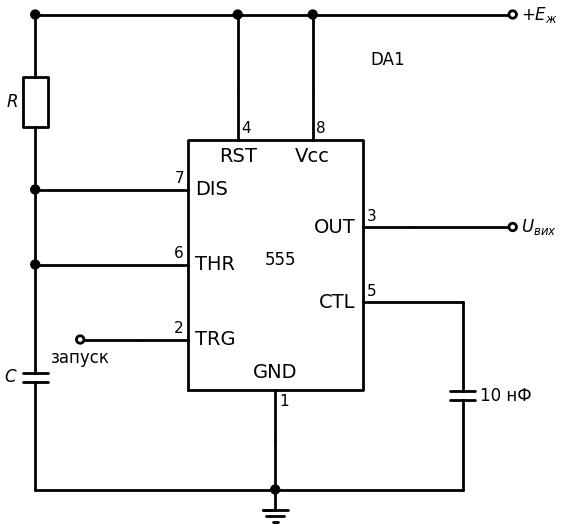

In [6]:
# Таймер 555 у чекальному режимі (одновібратор)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (t := elm.Ic555().at((4, 0)).anchor('GND'))
        d += elm.Label().at((t.OUT[0] - 0.6, t.Vcc[1] + 0.5)).label('DA1')
        top = t.Vcc[1] + 1.5; bot = t.GND[1] - 1.0
        d += W(t.Vcc, (t.Vcc[0], top)); d += W(t.RST, (t.RST[0], top)); d += W((-0.8, top), (t.OUT[0] + 2.0, top))
        d += elm.Dot().at((t.Vcc[0], top)); d += elm.Dot().at((t.RST[0], top)); d += elm.Dot().at((-0.8, top))
        d += elm.Dot(open=True).at((t.OUT[0] + 2.0, top)).label('$+E_ж$', loc='right')
        d += elm.Resistor().at((-0.8, top)).to((-0.8, t.DIS[1])).label('$R$', loc='top'); d += W((-0.8, t.DIS[1]), t.DIS); d += elm.Dot().at((-0.8, t.DIS[1]))
        d += W((-0.8, t.DIS[1]), (-0.8, t.THR[1])); d += W((-0.8, t.THR[1]), t.THR); d += elm.Dot().at((-0.8, t.THR[1]))
        d += elm.Capacitor().at((-0.8, t.THR[1])).to((-0.8, bot)).label('$C$', loc='top')
        d += W(t.TRG, (0.1, t.TRG[1])); d += elm.Dot(open=True).at((0.1, t.TRG[1])).label('запуск', loc='bottom')
        d += W((-0.8, bot), (t.CTL[0] + 1.0, bot)); d += W(t.GND, (t.GND[0], bot)); d += elm.Dot().at((t.GND[0], bot)); d += elm.Ground().at((t.GND[0], bot))
        d += W(t.CTL, (t.CTL[0] + 1.0, t.CTL[1])); d += elm.Capacitor().at((t.CTL[0] + 1.0, t.CTL[1])).to((t.CTL[0] + 1.0, bot)).label('10 нФ', loc='bottom')
        d += W(t.OUT, (t.OUT[0] + 2.0, t.OUT[1])); d += elm.Dot(open=True).at((t.OUT[0] + 2.0, t.OUT[1])).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: одновібратор на таймері 555 (PySpice) <a class="anchor" id="ne555-oneshot-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Модель біполярного таймера 555, $E_ж = 5$ В. На вхід TRG подано короткий спад до 0 тривалістю 5 мкс. Тривалість вихідного імпульсу $\approx 1{,}1RC$ і не залежить від тривалості запуску (поки запуск коротший за $t_і$).

</div>

In [7]:
# Таймер 555 у чекальному режимі
def ne555_oneshot(R_k=10.0, C_nF=10.0):
    R, C = R_k * 1e3, C_nF * 1e-9
    ti0 = 1.1 * R * C
    c = Circuit('555 one-shot'); c.include(spice_model('BIP-555.lib'))
    c.V(1, 'vcc', c.gnd, 5)
    c.PulseVoltageSource('t', 'trg', c.gnd, initial_value=5, pulsed_value=0, delay_time=0.3 * ti0 + 20e-6, rise_time=0.2e-6,
                         fall_time=0.2e-6, pulse_width=5e-6, period=1)
    c.X(1, '555bip', 'vcc', c.gnd, 'thr', 'vcc', 'ctl', 'thr', 'out', 'trg')     # THR і DIS з'єднані з C
    c.R(1, 'vcc', 'thr', R); c.C(1, 'thr', c.gnd, C); c.C(2, 'ctl', c.gnd, 10e-9)
    t, v = tran(c, ti0 / 500, 2.2 * ti0)
    u = v['out']; up = t[1:][(u[1:] > 2.5) & (u[:-1] <= 2.5)]; dn = t[1:][(u[1:] < 2.5) & (u[:-1] >= 2.5)]
    up = up[up > 0.3 * ti0]; dn = dn[dn > up[0]] if len(up) else dn
    ti = (dn[0] - up[0]) if len(up) and len(dn) else np.nan
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t * 1e3, v['trg'], color='#9E9E9E', label='TRG (запуск)'); ax.plot(t * 1e3, u, color='#F44336', label='вихід')
    ax.plot(t * 1e3, v['thr'], color='#2196F3', label='$u_C$'); ax.axhline(5 * 2 / 3, color='k', ls=':', lw=1)
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='center right', fontsize=9)
    ax.set_title(f'tі = {ti*1e3:.3f} мс;  формула 1,1RC = {ti0*1e3:.3f} мс')
    plt.tight_layout(); plt.show()

interact(ne555_oneshot,
         R_k=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='R (кОм)'),
         C_nF=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='C (нФ)'));

interactive(children=(FloatSlider(value=10.0, description='R (кОм)', min=1.0, step=1.0), FloatSlider(value=10.…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Запускальний імпульс довший за $t_і$ «ламає» одновібратор.** У всіх розглянутих схемах (ОП, логіка, 555) поки діє запуск, схема не може повернутися в стійкий стан, і вихідний імпульс розтягується на всю тривалість запуску. Тому на вхід ставлять диференціювальне коло (конденсатор + резистор, часто з діодом), яке перетворює фронт запускального сигналу на короткий імпульс. Друге обмеження — час відновлення: запуск раніше, ніж конденсатор повернувся у вихідний стан, дає коротший імпульс.

</div>

---
### ⚡ Практичне застосування: одновібратори

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Задача | Рішення |
|---|---|
| Усунення брязкоту кнопки | одновібратор з $t_і$ = 10…50 мс (555, 74HC123) |
| Реле часу (вимкнення світла через 1 хв) | 555 у чекальному режимі, $R$ = 1 МОм, $C$ = 47 мкФ |
| Сторожовий таймер (watchdog) | перезапускуваний одновібратор (74HC123), вихід — скидання МК |
| Детектор пропуску імпульсу | перезапускуваний одновібратор з $t_і$ трохи більшою за період |
| Тахометр / частотомір | одновібратор + ФНЧ: середнє ∝ $f\cdot t_і$ |
| ШІМ-модулятор | 555 у чекальному режимі, модуляція через CTL |

</div>

---
### ✅ Питання для самоперевірки: одновібратори

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чим одновібратор відрізняється від мультивібратора?</summary>

> **Відповідь:** Має один стійкий стан; генерує один імпульс нормованої тривалості на кожен запуск, а не безперервні коливання.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як із мультивібратора на ОП отримати одновібратор?</summary>

> **Відповідь:** Діодом паралельно конденсатору обмежити напругу на ньому ($U_{пр}$ менше порогу $\gamma U_{нас}$) — один стан стає стійким.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Яка тривалість імпульсу одновібратора на КМОН-елементах?</summary>

> **Відповідь:** $t_і = RC\ln\frac{E_ж}{E_ж - U_{пор}} \approx 0{,}69RC$ при $U_{пор} = E_ж/2$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чому у таймера 555 $t_і = 1{,}1RC$?</summary>

> **Відповідь:** Конденсатор заряджається від 0 до $\frac23E_ж$ з прагненням до $E_ж$: $t = RC\ln3 \approx 1{,}1RC$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Що таке час відновлення одновібратора?</summary>

> **Відповідь:** Час повернення RC-кола у вихідний стан після імпульсу; до його закінчення повторний запуск дає неправильну (коротшу) тривалість.

</details>

---
### 📝 Задачі для самостійного розв'язання: одновібратори


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Одновібратор на ОП: $R = 100$ кОм, $C = 0{,}1$ мкФ, $R_1 = R_2$, $U_{нас} = 13$ В. Знайдіть $t_і$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $\gamma = 0{,}5$; $t_і = 10^{-2}\ln\frac{1 + 0{,}6/13}{0{,}5} \approx 7{,}4$ мс.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Таймер 555 має формувати імпульс 1 с; $C = 10$ мкФ. Знайдіть $R$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 1/(1{,}1\cdot10^{-5}) \approx 91$ кОм.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** КМОН-одновібратор на АБО-НЕ з $C = 100$ нФ має формувати 1 мс. Знайдіть $R$; як зміниться $t_і$, якщо поріг елемента 0,4$E_ж$?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 10^{-3}/(0{,}693\cdot10^{-7}) \approx 14{,}4$ кОм; при $U_{пор} = 0{,}4E_ж$: $t_і = RC\ln(1/0{,}6) = 0{,}51RC$ — на 26 % коротше.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Одновібратор | Тривалість імпульсу |
|---|---|
| На ОП (з діодом на $C$) | $t_і = RC\ln\frac{1 + U_{пр}/U_{нас}}{1 - \gamma} \approx 0{,}69RC$ при $\gamma = 0{,}5$ |
| На КМОН-елементах АБО-НЕ | $t_і = RC\ln\frac{E_ж}{E_ж - U_{пор}} \approx 0{,}69RC$ |
| На таймері 555 | $t_і = RC\ln3 \approx 1{,}1RC$ |

**Головні висновки.** Одновібратор — мультивібратор з одним «забороненим» перемиканням: зовнішній запуск переводить його в квазістійкий стан, тривалість якого задає перезаряд RC-кола до порогу. Тривалість визначається сталою часу і відношенням порогу до рушійної напруги; у таймера 555 пороги задані внутрішнім дільником, тому точність і стабільність найвищі. Для правильної роботи запуск має бути коротшим за $t_і$, а період запуску — довшим за $t_і + t_{від}$.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Camenzind H. Designing Analog Chips. — Virtualbookworm, 2005.
7. Texas Instruments. Designing with the SN74HC123 / CD4538 monostable multivibrators (application notes).

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 13. Мультивібратори](Тема_13_Мультивібратори.ipynb)</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*